# ResilienceAI
Synthetic emergency-report analysis • reproducible seed 42 • educational prototype

Run **Runtime → Run all** in Google Colab (CPU). No credentials, downloads, external datasets, or APIs are used. All people, sources, locations, observations and verification outcomes are fictional. This is a decision-support demonstration, not an emergency dispatch system. Human review is required. All confidence values are **uncalibrated heuristics**, not probabilities of truth.

We distinguish incident classification from claim verification. A classifier can identify a flood report without establishing whether flooding actually occurred.

In [1]:
import sys, subprocess, importlib.util
required = {'numpy':'numpy', 'pandas':'pandas', 'sklearn':'scikit-learn', 'matplotlib':'matplotlib'}
missing = [pkg for mod,pkg in required.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
import re, json, math, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score
from sklearn.metrics.pairwise import cosine_similarity
SEED = 42
rng = np.random.default_rng(SEED)
OUT = Path('resilienceai_outputs'); OUT.mkdir(exist_ok=True)
print('Python', platform.python_version())

Python 3.12.14


## 1. Generate exactly 250 reports
50 fictional events × 5 reports. Each event has two independent sources agreeing, a copied report, a near-copy, and an opposing observation. Copies retain their original provenance group, so repetition does not create independent corroboration. Ground truth is stored only for evaluation; the operational evidence engine never reads it.

The first 30 events train the classifier; 20 entirely separate events test it. Training and test wording families differ to reduce template leakage. Synthetic performance still says nothing about real-world accuracy.

In [2]:
phrases = {
 'fire': ['flames and smoke rising', 'building burning with intense heat', 'visible blaze consuming structure', 'active combustion with thick fumes'],
 'flood': ['flood water covering streets', 'river overflow inundating homes', 'rising water submerging roads', 'inundation after heavy rainfall'],
 'medical': ['injured person needs medical assistance', 'patient requires urgent ambulance', 'unconscious resident needs paramedics', 'severe injury awaiting emergency treatment'],
 'power': ['power outage leaves homes dark', 'electrical grid service interrupted', 'electricity unavailable across neighborhood', 'blackout affecting local buildings'],
 'road': ['road blocked by fallen tree', 'traffic obstruction prevents passage', 'debris closes vehicle route', 'street impassable due to barrier']}
rows=[]
for event in range(50):
    kind=list(phrases)[event % 5]
    split='train' if event < 30 else 'test'
    phrase=phrases[kind][int(rng.integers(0,2)) + (0 if split=='train' else 2)]
    truth=bool(rng.integers(0,2))
    location=f'Fictional Sector {event:02d}'
    for j in range(5):
        stance=truth if j<4 else not truth
        text=f"{phrase} at {location}; condition {'present' if stance else 'absent'}."
        if j==3: text='Update: '+text+' Please verify.'
        if j==4: text='Conflicting observation: '+text
        rows.append(dict(report_id=f'R{event:02d}{j}',event_id=f'E{event:02d}',
            location=location, timestamp=(pd.Timestamp('2030-01-01',tz='UTC')+pd.Timedelta(minutes=event*60+j)).isoformat(),
            source_id=f'S{(event+j)%12:02d}', provenance=f'E{event:02d}-origin{j if j in (0,1,4) else 0}',
            text=text, incident_label=kind, split=split, truth_present=truth,
            observed_present=stance, severity='high' if kind in ('fire','medical') else 'moderate'))
reports=pd.DataFrame(rows)
assert len(reports)==250 and reports.report_id.is_unique
# Historical adjudications predate these events and are independent synthetic evidence.
history=pd.DataFrame([dict(source_id=f'S{i:02d}', correct=4+i%6, incorrect=1+i%3,
                          adjudication_basis='fictional historical reviewer records') for i in range(12)])
history['reliability_heuristic']=(history.correct+1)/(history.correct+history.incorrect+2)
display(reports.head(), history)
reports.to_csv(OUT/'synthetic_reports.csv',index=False)
history.to_csv(OUT/'source_history.csv',index=False)

,report_id,event_id,location,timestamp,source_id,provenance,text,incident_label,split,truth_present,observed_present,severity
0,R000,E00,Fictional Sector 00,2030-01-01T00:00:00+00:00,S00,E00-origin0,flames and smoke rising at Fictional Sector 00...,fire,train,True,True,high
1,R001,E00,Fictional Sector 00,2030-01-01T00:01:00+00:00,S01,E00-origin1,flames and smoke rising at Fictional Sector 00...,fire,train,True,True,high
2,R002,E00,Fictional Sector 00,2030-01-01T00:02:00+00:00,S02,E00-origin0,flames and smoke rising at Fictional Sector 00...,fire,train,True,True,high
3,R003,E00,Fictional Sector 00,2030-01-01T00:03:00+00:00,S03,E00-origin0,Update: flames and smoke rising at Fictional S...,fire,train,True,True,high
4,R004,E00,Fictional Sector 00,2030-01-01T00:04:00+00:00,S04,E00-origin4,Conflicting observation: flames and smoke risi...,fire,train,True,False,high


,source_id,correct,incorrect,adjudication_basis,reliability_heuristic
0,S00,4,1,fictional historical reviewer records,0.714286
1,S01,5,2,fictional historical reviewer records,0.666667
2,S02,6,3,fictional historical reviewer records,0.636364
3,S03,7,1,fictional historical reviewer records,0.800000
4,S04,8,2,fictional historical reviewer records,0.750000
5,S05,9,3,fictional historical reviewer records,0.714286
6,S06,4,1,fictional historical reviewer records,0.714286
7,S07,5,2,fictional historical reviewer records,0.666667
8,S08,6,3,fictional historical reviewer records,0.636364
9,S09,7,1,fictional historical reviewer records,0.800000


## 2. Incident classification
TF–IDF word and bigram features plus logistic regression use only report text. No truth, source, severity, event ID or structured observation is a model feature. The maximum model score is uncalibrated; unfamiliar vocabulary triggers abstention. The threshold 0.35 is an illustrative policy choice, not tuned on the test set.

              precision    recall  f1-score   support

        fire       1.00      0.75      0.86        20
       flood       0.33      1.00      0.50        20
     medical       0.36      0.45      0.40        20
       power       0.00      0.00      0.00        20
        road       0.00      0.00      0.00        20

    accuracy                           0.44       100
   macro avg       0.34      0.44      0.35       100
weighted avg       0.34      0.44      0.35       100



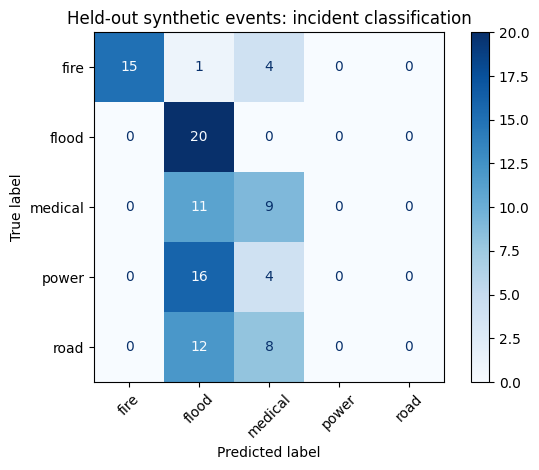

In [3]:
train=reports[reports.split=='train']; test=reports[reports.split=='test']
model=make_pipeline(TfidfVectorizer(ngram_range=(1,2)),LogisticRegression(max_iter=1000,random_state=SEED))
model.fit(train.text,train.incident_label)
def classify(text):
    if not isinstance(text,str) or not text.strip(): return ('unknown',0.0)
    vector=model[0].transform([text])
    if vector.nnz==0: return ('unknown',0.0)
    scores=model.predict_proba([text])[0]; best=int(scores.argmax()); score=float(scores[best])
    return (str(model.classes_[best]) if score>=0.35 else 'unknown',score)
reports[['predicted_type','classification_confidence_heuristic']]=pd.DataFrame(
    [classify(t) for t in reports.text],index=reports.index)
pred=model.predict(test.text)
print(classification_report(test.incident_label,pred,zero_division=0))
macro_f1=float(f1_score(test.incident_label,pred,average='macro'))
ConfusionMatrixDisplay.from_predictions(test.incident_label,pred,xticks_rotation=45,cmap='Blues')
plt.title('Held-out synthetic events: incident classification'); plt.tight_layout()
plt.savefig(OUT/'classification.png',dpi=140); plt.show()

## 3. Duplicate and contradiction detection
Normalize text for exact duplicates; use character TF–IDF cosine similarity ≥ 0.80 for near duplicates. Compare only within the same event, location and 30-minute window. Contradictory structured observations take precedence over lexical similarity. A shared provenance is always grouped together.

Event IDs, provenance, location and present/absent observations are structured synthetic inputs, **not facts extracted by NLP**. Opposing observations within a window flag a potential contradiction; changing conditions can also explain them. Unknown or missing observations require review. No general semantic contradiction detector is claimed. The pairwise method is O(n²), suitable for 250 reports.

In [4]:
def normalize(text):
    return re.sub(r'\W+',' ',str(text).lower()).strip()
def scoped(a,b):
    try:
        return (a.event_id==b.event_id and a.location==b.location and
                abs(pd.Timestamp(a.timestamp)-pd.Timestamp(b.timestamp))<=pd.Timedelta(minutes=30))
    except (ValueError,TypeError): return False
def valid_stance(x): return isinstance(x,(bool,np.bool_))
def detect(df):
    if len(df)<2: return pd.DataFrame(columns=['a','b','relation','similarity'])
    texts=df.text.fillna('').astype(str)
    if not any(t.strip() for t in texts): return pd.DataFrame(columns=['a','b','relation','similarity'])
    sim=cosine_similarity(TfidfVectorizer(analyzer='char_wb',ngram_range=(3,5)).fit_transform(texts))
    records=[]; items=list(df.itertuples())
    for i,a in enumerate(items):
        for j in range(i+1,len(items)):
            b=items[j]
            if not scoped(a,b): continue
            relation=None
            if valid_stance(a.observed_present) and valid_stance(b.observed_present) and a.observed_present!=b.observed_present:
                relation='contradiction'
            elif a.provenance==b.provenance or normalize(a.text)==normalize(b.text): relation='duplicate'
            elif sim[i,j]>=0.80: relation='near_duplicate'
            if relation: records.append(dict(a=a.report_id,b=b.report_id,relation=relation,similarity=float(sim[i,j])))
    return pd.DataFrame(records,columns=['a','b','relation','similarity'])
relations=detect(reports)
display(relations.head(12))
relations.to_csv(OUT/'report_relations.csv',index=False)

,a,b,relation,similarity
0,R000,R001,duplicate,1.000000
1,R000,R002,duplicate,1.000000
2,R000,R003,duplicate,0.838482
3,R000,R004,contradiction,0.809306
4,R001,R002,duplicate,1.000000
5,R001,R003,near_duplicate,0.838482
6,R001,R004,contradiction,0.809306
7,R002,R003,duplicate,0.838482
8,R002,R004,contradiction,0.809306
9,R003,R004,contradiction,0.678589


## 4. Claim ledger and escalation
Each claim asks whether a specific incident is present at a location during an event window. Historical reliability is Laplace-smoothed (correct+1)/(correct+incorrect+2); unknown sources get 0.5. Current-event truth never updates reliability automatically.

Duplicate links form connected components; each component contributes at most the largest source weight to each stance. This conservative policy may merge independent similar reports. Confidence = |support−opposition|/(support+opposition+1), an **uncalibrated heuristic** with a one-unit uncertainty prior. Any opposing evidence forces `disputed` and human review regardless of confidence. `corroborated` requires two independent groups and score ≥ 0.50; it never means verified. Negative evidence is retained. High-severity claims escalate even when confidence is low.

In [5]:
weights=history.set_index('source_id').reliability_heuristic.to_dict()
def ledger(df,links):
    output=[]
    for event,g in df.groupby('event_id',sort=True):
        parent={r:r for r in g.report_id}
        def root(x):
            while parent[x]!=x:
                parent[x]=parent[parent[x]]; x=parent[x]
            return x
        for link in links.itertuples():
            if link.relation in ('duplicate','near_duplicate') and link.a in parent and link.b in parent:
                parent[root(link.b)]=root(link.a)
        grouped={}; evidence=[]; unknown=False
        for r in g.itertuples():
            if not valid_stance(r.observed_present): unknown=True; continue
            key=(root(r.report_id),bool(r.observed_present))
            weight=weights.get(r.source_id,0.5)
            grouped[key]=max(grouped.get(key,0),weight)
            evidence.append({'report':r.report_id,'source':r.source_id,'provenance':r.provenance,
                             'stance':'supports' if r.observed_present else 'opposes','weight_heuristic':round(weight,3)})
        support=sum(v for (k,s),v in grouped.items() if s)
        oppose=sum(v for (k,s),v in grouped.items() if not s)
        confidence=abs(support-oppose)/(support+oppose+1)
        count=sum(1 for k,s in grouped if s==(support>=oppose))
        status=('disputed' if support and oppose else 'insufficient' if not grouped or unknown else
                'corroborated' if count>=2 and confidence>=0.5 else 'unconfirmed')
        types=sorted(set(g.predicted_type)-{'unknown'})
        escalation=('human review: conflicting evidence' if status=='disputed' else
                    'human review: high severity' if (g.severity=='high').any() else
                    'human review: insufficient evidence' if status!='corroborated' else 'monitor; human validation pending')
        first=g.iloc[0]
        output.append(dict(event_id=event,claim=f"{', '.join(types) or 'unknown incident'} present at {first.location}",
            evidence=json.dumps(evidence),status=status,confidence_heuristic=round(confidence,4),
            escalation=escalation,support_weight=round(support,3),opposition_weight=round(oppose,3),
            independent_groups=len(set(k for k,s in grouped)),confidence_label='uncalibrated heuristic'))
    return pd.DataFrame(output)
claims=ledger(reports,relations)
display(claims[['claim','evidence','status','confidence_heuristic','escalation']].head(10))
claims.to_csv(OUT/'claim_evidence_status.csv',index=False)

,claim,evidence,status,confidence_heuristic,escalation
0,fire present at Fictional Sector 00,"[{""report"": ""R000"", ""source"": ""S00"", ""provenan...",disputed,0.0196,human review: conflicting evidence
1,flood present at Fictional Sector 01,"[{""report"": ""R010"", ""source"": ""S01"", ""provenan...",disputed,0.0341,human review: conflicting evidence
2,medical present at Fictional Sector 02,"[{""report"": ""R020"", ""source"": ""S02"", ""provenan...",disputed,0.0341,human review: conflicting evidence
3,power present at Fictional Sector 03,"[{""report"": ""R030"", ""source"": ""S03"", ""provenan...",disputed,0.0541,human review: conflicting evidence
4,road present at Fictional Sector 04,"[{""report"": ""R040"", ""source"": ""S04"", ""provenan...",disputed,0.0476,human review: conflicting evidence
5,fire present at Fictional Sector 05,"[{""report"": ""R050"", ""source"": ""S05"", ""provenan...",disputed,0.0341,human review: conflicting evidence
6,flood present at Fictional Sector 06,"[{""report"": ""R060"", ""source"": ""S06"", ""provenan...",disputed,0.0196,human review: conflicting evidence
7,medical present at Fictional Sector 07,"[{""report"": ""R070"", ""source"": ""S07"", ""provenan...",disputed,0.0341,human review: conflicting evidence
8,power present at Fictional Sector 08,"[{""report"": ""R080"", ""source"": ""S08"", ""provenan...",disputed,0.0341,human review: conflicting evidence
9,road present at Fictional Sector 09,"[{""report"": ""R090"", ""source"": ""S09"", ""provenan...",disputed,0.0541,human review: conflicting evidence


## 5. Resilience tests
These assertions test safety properties of this prototype, not real-world readiness. Stress cases cover replay amplification, missing sources, blank and unfamiliar text, contradictions, malformed observations, shuffled order, time/location isolation, and truth leakage. A separate clean-evidence scenario exercises the non-disputed path.

In [6]:
checks=[]
def check(name,condition):
    assert condition,name
    checks.append(dict(test=name,result='PASS'))
check('Exactly 250 synthetic reports',len(reports)==250)
check('No event leakage',set(train.event_id).isdisjoint(test.event_id))
check('Blank input abstains',classify(None)==('unknown',0.0) and classify('  ')==('unknown',0.0))
check('Unseen vocabulary abstains',classify('zzzxxyy qqqwww')[0]=='unknown')
check('All injected contradictions detected',sum(relations.relation=='contradiction')==200)
check('All claims with opposing evidence disputed',claims.status.eq('disputed').all())
base=reports[reports.event_id=='E00'].copy()
base_links=detect(base); baseline=ledger(base,base_links).iloc[0]
replays=pd.concat([base]+[base.iloc[[0]].assign(report_id=f'replay{i}') for i in range(100)],ignore_index=True)
stressed=ledger(replays,detect(replays)).iloc[0]
check('100 replays cannot inflate confidence',baseline.confidence_heuristic==stressed.confidence_heuristic)
check('Replay groups unchanged',baseline.independent_groups==stressed.independent_groups)
check('Order invariance',ledger(base.sample(frac=1,random_state=7),base_links).confidence_heuristic.iloc[0]==baseline.confidence_heuristic)
other=base.iloc[:2].copy(); other.loc[other.index[1],'location']='Different fictional place'
check('Different locations isolated',detect(other).empty)
other=base.iloc[:2].copy(); other.loc[other.index[1],'timestamp']='2030-01-02T00:00:00+00:00'
check('Stale reports isolated',detect(other).empty)
unknown=base.iloc[:1].copy(); unknown['source_id']='unknown-source'; unknown['observed_present']=True
check('Unknown source neutral prior',ledger(unknown,detect(unknown)).support_weight.iloc[0]==0.5)
missing=base.iloc[:1].copy(); missing['observed_present']=None
check('Missing observation review',ledger(missing,detect(missing)).status.iloc[0]=='insufficient')
flipped=reports.copy(); flipped['truth_present']=~flipped.truth_present
check('Truth labels never affect ledger',ledger(flipped,relations).equals(claims))
check('Empty pair detector',detect(reports.iloc[:0]).empty)
clean=base.iloc[:2].copy(); clean['observed_present']=True
clean['text']=['flames visible in north building','separate witness reports burning roof']
clean_result=ledger(clean,detect(clean)).iloc[0]
check('Independent agreement path',clean_result.status=='corroborated')
check('Confidence bounded',claims.confidence_heuristic.between(0,1).all())
test_results=pd.DataFrame(checks); display(test_results)
test_results.to_csv(OUT/'resilience_tests.csv',index=False)
summary={'synthetic_reports':len(reports),'held_out_reports':len(test),'held_out_macro_f1':macro_f1,
         'resilience_tests_passed':len(checks),'confidence':'uncalibrated heuristic'}
(OUT/'run_summary.json').write_text(json.dumps(summary,indent=2))
print(json.dumps(summary,indent=2))

{
  "synthetic_reports": 250,
  "held_out_reports": 100,
  "held_out_macro_f1": 0.3514285714285714,
  "resilience_tests_passed": 17,
  "confidence": "uncalibrated heuristic"
}


,test,result
0,Exactly 250 synthetic reports,PASS
1,No event leakage,PASS
2,Blank input abstains,PASS
3,Unseen vocabulary abstains,PASS
4,All injected contradictions detected,PASS
5,All claims with opposing evidence disputed,PASS
6,100 replays cannot inflate confidence,PASS
7,Replay groups unchanged,PASS
8,Order invariance,PASS
9,Different locations isolated,PASS


## 6. Evidence dashboard
All generated events deliberately contain conflicts, so the main status chart is entirely disputed. This is a stress-test dataset, not a realistic incident prevalence distribution. The clean scenario above tests agreement separately.

Exports:
resilienceai_outputs/claim_evidence_status.csv
resilienceai_outputs/classification.png
resilienceai_outputs/evidence_dashboard.png
resilienceai_outputs/report_relations.csv
resilienceai_outputs/resilience_tests.csv
resilienceai_outputs/run_summary.json
resilienceai_outputs/source_history.csv
resilienceai_outputs/synthetic_reports.csv


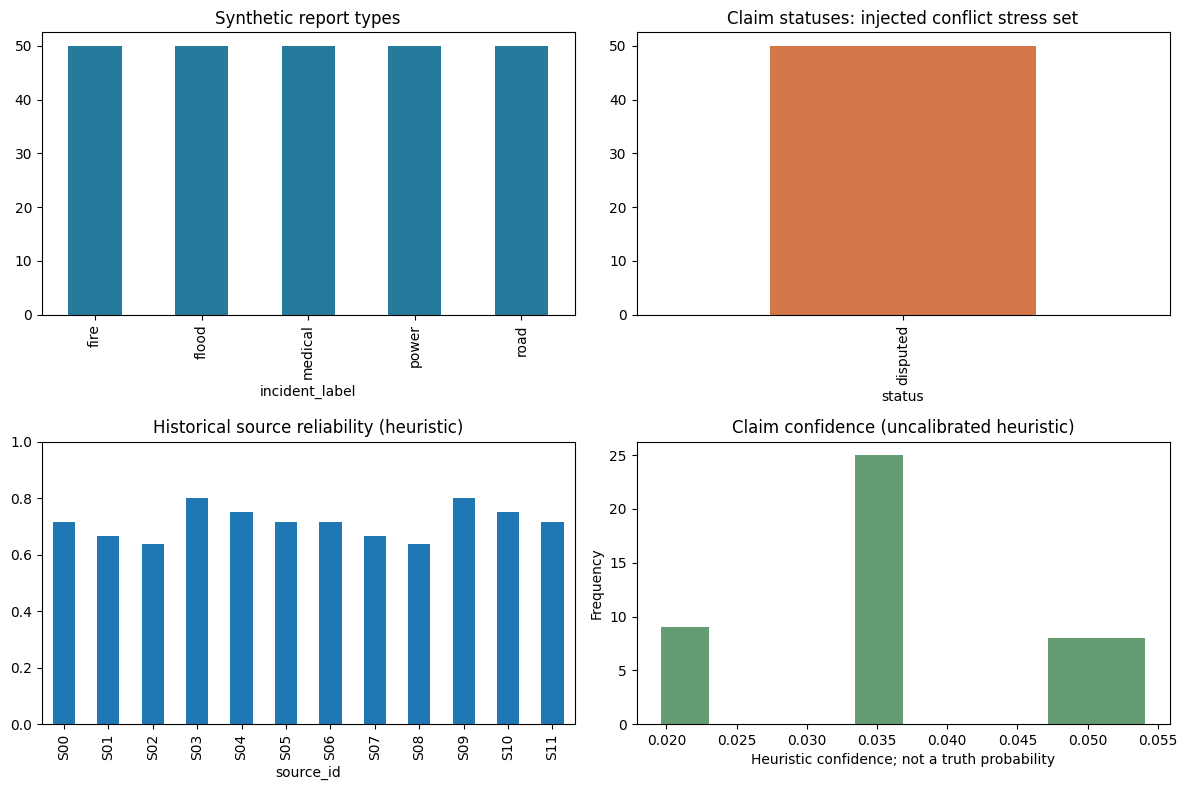

In [7]:
fig,axes=plt.subplots(2,2,figsize=(12,8))
reports.incident_label.value_counts().plot.bar(ax=axes[0,0],color='#267b9c',title='Synthetic report types')
claims.status.value_counts().plot.bar(ax=axes[0,1],color='#d47748',title='Claim statuses: injected conflict stress set')
history.plot.bar(x='source_id',y='reliability_heuristic',ax=axes[1,0],legend=False,title='Historical source reliability (heuristic)')
axes[1,0].set_ylim(0,1)
claims.confidence_heuristic.plot.hist(ax=axes[1,1],bins=10,color='#659c71',title='Claim confidence (uncalibrated heuristic)')
axes[1,1].set_xlabel('Heuristic confidence; not a truth probability')
plt.tight_layout(); plt.savefig(OUT/'evidence_dashboard.png',dpi=140); plt.show()
print('Exports:',*[str(f) for f in sorted(OUT.iterdir())],sep='\n')

## Interpretation and next steps
Conflicts remain visible instead of being voted away. Repetition is discounted by provenance and duplicate grouping. Reliability reflects independent fictional historical adjudications, not agreement with the model. Human review would record a decision, reviewer, timestamp and evidence before updating history.

Limitations: trusted structured metadata, English template data, lexical duplicate matching, an arbitrary 30-minute window, no source authentication, and no semantic extraction. Missing or false provenance can defeat copy detection; unrelated similar reports can be over-merged. A real deployment needs authenticated provenance, temporal claim extraction, privacy review, independent adjudication, language coverage and representative out-of-distribution evaluation. Confidence calibration would require separately held-out, adjudicated real-world outcomes and reliability diagrams/Brier scores; these synthetic heuristic scores are not calibrated.

To experiment, edit the seed, generation templates, thresholds or historical records and rerun all cells. Do not insert real emergency or personal data into this demo.

## Observed validation result
The delivered run passed all **17 resilience assertions**. Incident classification achieved **0.3514 macro F1** on 100 reports from 20 held-out events using different wording families. This weak vocabulary-shift result is intentional evidence of a baseline limitation, not a successful robustness claim. Review the confusion matrix before interpreting predictions. The assertions validate evidence-handling properties; they do not assert classifier quality. Expand training diversity and validate independently before attempting practical use.

Execution note: all code cells were executed in order in a fresh local Python process via IPython, with embedded outputs. Google Colab compatibility is based on standard Python/Colab APIs; the notebook has not been executed on Google's hosted runtime.